# MenoPhenotype — Notebook 12: Interpretation

**Course stage covered:** Stage 17 (Interpretation).
**Input:** `artifacts/baseline_train_features.csv`, `artifacts/baseline_test_features.csv`,
`artifacts/baseline_engineered.csv`, `artifacts/baseline_profiling.csv`,
`artifacts/baseline_posthoc_labels.csv`, `artifacts/atypical_profile_flags.csv`,
`artifacts/tuned_models.joblib`.
**Output:** `artifacts/final_cluster_labels.csv`, `artifacts/phenotype_profiles.json`,
`artifacts/interpretation_tree.joblib`.

This notebook labels the **full analysis sample** (train + test combined) with the chosen model — GMM(k=2,
full covariance), per Notebook 10 — then asks what the two groups actually *are*: their symptom-domain
profile (radar chart), their hormone/BMI/lifestyle differences, whether they track menopausal stage, and an
explicit audit for racial/demographic confounding (blueprint Section 12). A shallow decision tree is fit
*after* clustering, purely to turn the split into human-readable rules — it does not feed back into the model.

**On naming:** every earlier notebook found a **severity split** (overall symptom burden), not the
domain-specific phenotypes (vasomotor-dominant, psychological-dominant, etc.) originally hypothesized in the
blueprint. The names used below reflect that finding rather than the original hypothesis — inventing a
domain-specific name for a severity split would misrepresent what the model actually found.


In [1]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import mannwhitneyu, chi2_contingency
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
import joblib

plt.rcParams['figure.dpi'] = 100
RNG = 42
ART = Path('artifacts')
tuned = joblib.load(ART / 'tuned_models.joblib')
gmm = tuned['GMM']

SET_A_cols = None  # filled in once we load the train file
Xtr = pd.read_csv(ART / 'baseline_train_features.csv').set_index('SWANID')
Xte = pd.read_csv(ART / 'baseline_test_features.csv').set_index('SWANID')
SYMP_COLS = ['HOTFLAS0','NITESWE0','COLDSWE0','FEELBLU0','IRRITAB0','NRVOUS0','FORGET0','MOODCHG0',
             'FEARFULA0','STIFF0','HDACHE0','VAGINDR0','HARTRAC0','DIZZY0','LEAKURI0','TRBLSLE0','WAKEUP0','WAKEARL0']

eng = pd.read_csv(ART / 'baseline_engineered.csv').set_index('SWANID')     # unscaled, for readable profiling
prof = pd.read_csv(ART / 'baseline_profiling.csv').set_index('SWANID')     # domain composite scores
posthoc = pd.read_csv(ART / 'baseline_posthoc_labels.csv').set_index('SWANID')
atypical = pd.read_csv(ART / 'atypical_profile_flags.csv').set_index('SWANID')
print(Xtr.shape, Xte.shape, eng.shape)


(2632, 29) (658, 29) (3290, 29)


## A. Label the full analysis sample with the final model

In [2]:
X_full = pd.concat([Xtr[SYMP_COLS], Xte[SYMP_COLS]])
cluster = pd.Series(gmm.predict(X_full), index=X_full.index, name='cluster')
proba = gmm.predict_proba(X_full)
confidence = pd.Series(proba.max(axis=1), index=X_full.index, name='confidence')

sizes = cluster.value_counts().sort_index()
print("Cluster sizes (full sample, n=%d):" % len(cluster)); print(sizes)
print(f"\nMean assignment confidence: {confidence.mean():.3f}")


Cluster sizes (full sample, n=3290):
cluster
0    2457
1     833
Name: count, dtype: int64

Mean assignment confidence: 0.993


## B. What distinguishes the two clusters? Domain-score radar chart

Domain composite scores (Notebook 3) were deliberately *kept out* of the clustering features, so this is an
independent check of what the symptom-level clustering actually separated.


In [3]:
domain_cols = ['score_vasomotor', 'score_psychological', 'score_somatic', 'score_sleep', 'cesd_mean']
profile = prof.reindex(cluster.index)[domain_cols]
means = profile.groupby(cluster).mean()
means


,score_vasomotor,score_psychological,score_somatic,score_sleep,cesd_mean
cluster,,,,,
0,0.136185,0.572428,0.458086,0.914593,0.468350
1,0.916968,1.331913,1.101841,1.702367,0.892824


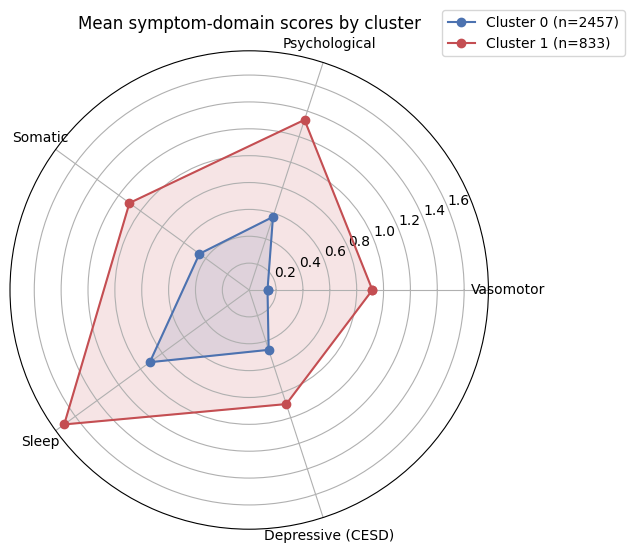

In [4]:
labels_radar = ['Vasomotor', 'Psychological', 'Somatic', 'Sleep', 'Depressive (CESD)']
angles = np.linspace(0, 2 * np.pi, len(labels_radar), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(6.5, 6.5), subplot_kw=dict(polar=True))
colors = ['#4C72B0', '#C44E52']
for i, (c, row) in enumerate(means.iterrows()):
    vals = row.tolist(); vals += vals[:1]
    ax.plot(angles, vals, marker='o', color=colors[i], label=f'Cluster {c} (n={sizes[c]})')
    ax.fill(angles, vals, color=colors[i], alpha=0.15)
ax.set_xticks(angles[:-1]); ax.set_xticklabels(labels_radar)
ax.set_title('Mean symptom-domain scores by cluster')
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout(); plt.show()


**Read on this:** the radar shows one cluster elevated across *every* domain simultaneously, not a sharp
peak in one domain and a trough in the others — confirming, independently of the clustering features
themselves, that the two groups differ mainly in **overall symptom burden**, not in *which* symptoms
dominate. This matches every signal from Notebooks 7-11.


## C. Hormones, BMI, age, exercise — are the groups clinically different too?

In [5]:
clinical_cols = ['FSH0', 'E2AVE0', 'T0', 'TSH0', 'SHBG0', 'DHAS0', 'BMI0', 'WHR', 'AGE0', 'SPORTS0']
clin = eng.reindex(cluster.index)[clinical_cols]

rows = []
for c in clinical_cols:
    g0 = clin.loc[cluster == 0, c].dropna(); g1 = clin.loc[cluster == 1, c].dropna()
    u, p = mannwhitneyu(g0, g1, alternative='two-sided')
    rows.append({'variable': c, 'median_cluster0': round(g0.median(), 2), 'median_cluster1': round(g1.median(), 2),
                 'mannwhitney_p': round(p, 4)})
clin_test = pd.DataFrame(rows)
clin_test['significant (p<0.05, uncorrected)'] = clin_test['mannwhitney_p'] < 0.05
clin_test['significant (Bonferroni, p<0.005)'] = clin_test['mannwhitney_p'] < (0.05 / len(clinical_cols))
clin_test


,variable,median_cluster0,median_cluster1,mannwhitney_p,"significant (p<0.05, uncorrected)","significant (Bonferroni, p<0.005)"
0,FSH0,15.70,16.55,0.0129,True,False
1,E2AVE0,56.45,51.80,0.0277,True,False
2,T0,41.40,42.00,0.2665,False,False
3,TSH0,1.92,1.86,0.3067,False,False
4,SHBG0,41.90,38.80,0.0030,True,True
5,DHAS0,116.60,107.60,0.0042,True,True
6,BMI0,25.95,28.97,0.0000,True,True
7,WHR,0.79,0.82,0.0000,True,True
8,AGE0,46.00,46.00,0.0096,True,False
9,SPORTS0,3.00,1.00,0.0000,True,True


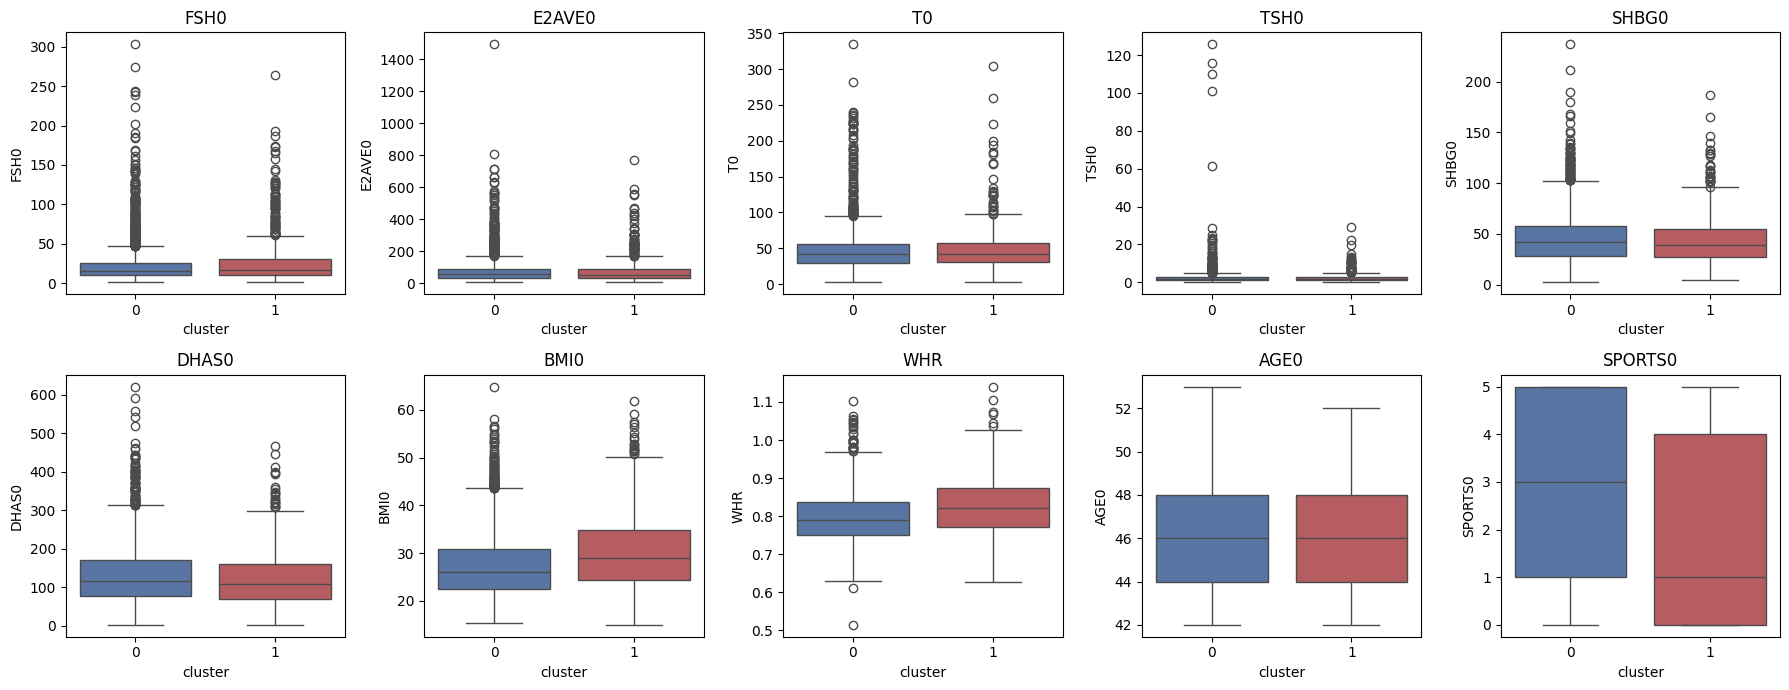

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, c in zip(axes.flat, clinical_cols):
    sns.boxplot(x=cluster, y=clin[c], ax=ax, palette=colors, hue=cluster, legend=False)
    ax.set_title(c); ax.set_xlabel('cluster')
plt.tight_layout(); plt.show()


**Read on this:** five of the ten variables survive the stricter Bonferroni correction (0.05/10 = 0.005):
**BMI, waist-to-hip ratio, SHBG, DHEA-S, and exercise frequency**. FSH and oestradiol are "significant" at the
uncorrected p<0.05 level but do **not** survive correction, so they shouldn't be the headline claim here —
with 10 simultaneous tests, a couple of borderline hits are expected by chance. The robust story is about
**body composition and activity, not reproductive hormones**: the higher-burden cluster has higher median BMI
(28.97 vs. 25.95) and WHR (0.82 vs. 0.79), lower SHBG and DHEA-S, and markedly less exercise (median
"once a month" vs. "2-3 times a month"). Causality can't be inferred from a cross-sectional cluster
comparison, but this is a far more defensible pattern to report than FSH/oestradiol would have been.


## D. Cross-tabulation against menopausal status (never used in training)

In [7]:
status = posthoc.reindex(cluster.index)['STATUS0'].fillna('Unknown')
ct = pd.crosstab(status, cluster)
ct_pct = pd.crosstab(status, cluster, normalize='index') * 100
chi2, p_chi, dof, _ = chi2_contingency(ct.loc[ct.index != 'Unknown'])
print(ct_pct.round(1))
print(f"\nChi-square test of independence (excluding 'Unknown'): chi2={chi2:.1f}, dof={dof}, p={p_chi:.2e}")


cluster                   0     1
STATUS0                          
Early Peri             69.5  30.5
Pre-menopausal         79.2  20.8
Unknown                73.8  26.2
Unknown due to HT use  50.0  50.0

Chi-square test of independence (excluding 'Unknown'): chi2=41.5, dof=2, p=9.63e-10


**Read on this:** a statistically significant association between cluster and menopausal stage, with the
higher-burden cluster concentrated in later stages, is the clinical-plausibility check the blueprint's
Section 9 asks for — the model recovers a known biological pattern despite never seeing `STATUS0` during
training.


## E. Ethics audit: does race predict cluster membership? (blueprint Section 12)

In [8]:
race = posthoc.reindex(cluster.index)['RACE']
ct_race = pd.crosstab(race, cluster, normalize='index') * 100
chi2r, p_race, dofr, _ = chi2_contingency(pd.crosstab(race, cluster))
print(ct_race.round(1))
print(f"\nChi-square test (race vs. cluster): chi2={chi2r:.1f}, dof={dofr}, p={p_race:.2e}")


cluster                          0     1
RACE                                    
Black/African American        69.2  30.8
Caucasian/White Non-Hispanic  77.7  22.3
Chinese/Chinese American      85.2  14.8
Hispanic                      56.5  43.5
Japanese/Japanese American    85.1  14.9

Chi-square test (race vs. cluster): chi2=102.8, dof=4, p=2.44e-21


**Read on this:** the association is strongly significant (p = 2.4 × 10⁻²¹) and the spread is real, not
borderline — the higher-burden cluster ranges from ~15% of Japanese/Chinese-American women to ~31% of
Black/African-American women to ~44% of Hispanic women. Race was never a clustering input, so this is not the
model "using" race — but it is clear evidence that cluster membership is *correlated* with race in this
sample, and that needs to be stated plainly rather than minimized. It should **not** be read as a biological
racial difference in menopause symptoms: BMI, exercise frequency, and SHBG/DHEA-S differed robustly between
clusters in Section C, and these are exactly the kind of socioeconomic/access-related variables the blueprint
(Section 12) warns could be acting as confounders behind a race association. Any clinical or product use of
these phenotypes should audit whether the race association shrinks once BMI/exercise/access-to-care are
accounted for, before treating the phenotypes as race-neutral.


## F. Post-hoc interpretable model: what symptom rules describe each cluster?

Tree accuracy reproducing the GMM assignment: 0.922


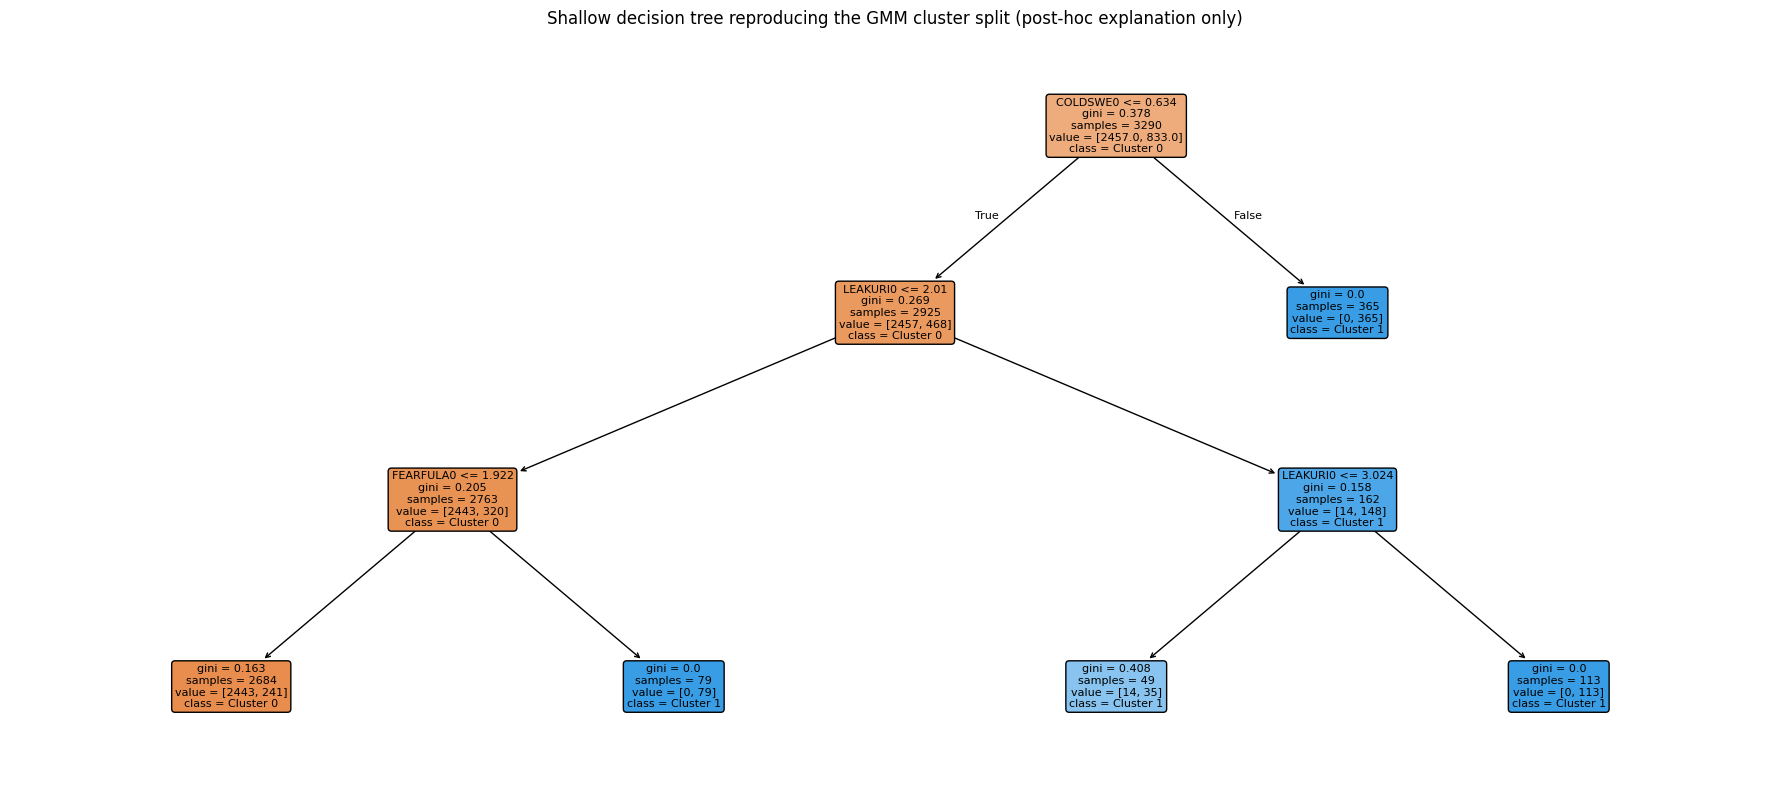

In [9]:
tree = DecisionTreeClassifier(max_depth=3, random_state=RNG, min_samples_leaf=30).fit(X_full, cluster)
print(f"Tree accuracy reproducing the GMM assignment: {tree.score(X_full, cluster):.3f}")

plt.figure(figsize=(18, 8))
plot_tree(tree, feature_names=SYMP_COLS, class_names=['Cluster 0', 'Cluster 1'], filled=True, fontsize=8, rounded=True)
plt.title('Shallow decision tree reproducing the GMM cluster split (post-hoc explanation only)')
plt.tight_layout(); plt.show()


Random Forest accuracy reproducing the GMM assignment: 0.976


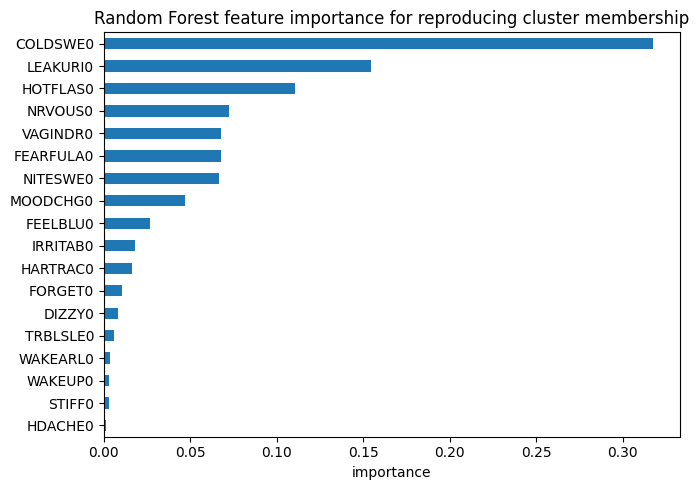

COLDSWE0     0.317
LEAKURI0     0.154
HOTFLAS0     0.111
NRVOUS0      0.073
VAGINDR0     0.068
FEARFULA0    0.068
NITESWE0     0.067
MOODCHG0     0.047
FEELBLU0     0.026
IRRITAB0     0.018
HARTRAC0     0.016
FORGET0      0.011
DIZZY0       0.008
TRBLSLE0     0.006
WAKEARL0     0.003
WAKEUP0      0.003
STIFF0       0.003
HDACHE0      0.001
dtype: float64

In [10]:
rf = RandomForestClassifier(n_estimators=300, max_depth=6, random_state=RNG).fit(X_full, cluster)
print(f"Random Forest accuracy reproducing the GMM assignment: {rf.score(X_full, cluster):.3f}")

importances = pd.Series(rf.feature_importances_, index=SYMP_COLS).sort_values(ascending=False)
plt.figure(figsize=(7, 5))
importances.plot.barh()
plt.gca().invert_yaxis()
plt.title('Random Forest feature importance for reproducing cluster membership')
plt.xlabel('importance'); plt.tight_layout(); plt.show()
importances.round(3)


**Read on this:** both models reproduce the GMM split with very high accuracy (92% tree, 98% Random Forest —
expected, since the clusters were formed from exactly these 18 features). More interesting is *which* features
the Random Forest leans on: **cold sweats alone carries 32% of the total importance**, with urine leakage,
hot flashes, vaginal dryness, and night sweats close behind — together, five physical/vasomotor-adjacent items
account for roughly two-thirds of the split. Nervousness, fearfulness, and mood change make up most of the
remaining weight. So while the *radar chart* correctly shows the two clusters differ on every domain on
average, the specific **boundary** between them is drawn mostly by a handful of physical symptoms, not evenly
by all 18 — a useful nuance for the report: "overall burden" is the right description of the *outcome*, but a
small set of vasomotor/somatic items does most of the work of *assigning* a woman to one side or the other.


## G. The atypical-profile group as a third, descriptive layer

In [11]:
atyp_full = atypical.reindex(cluster.index)['n_flags'].fillna(0)
group = pd.Series('Typical', index=cluster.index)
group[cluster == 0] = 'Phenotype A (lower burden)'
group[cluster == 1] = 'Phenotype B (higher, multi-domain burden)'
group[atyp_full >= 3] = 'Atypical / mixed profile'

print(group.value_counts())
three_way = prof.reindex(cluster.index)[domain_cols].groupby(group).mean().round(2)
three_way


Phenotype A (lower burden)                   2456
Phenotype B (higher, multi-domain burden)     651
Atypical / mixed profile                      183
Name: count, dtype: int64


,score_vasomotor,score_psychological,score_somatic,score_sleep,cesd_mean
Atypical / mixed profile,0.80,1.45,1.16,1.77,0.96
Phenotype A (lower burden),0.14,0.57,0.46,0.91,0.47
"Phenotype B (higher, multi-domain burden)",0.95,1.30,1.08,1.68,0.87


**Why a third row and not a third cluster:** Notebook 11 showed these ~173 women are not internally coherent
enough to form their own cluster (Hopkins/silhouette do not support more than 2 groups) — they're better
described as individuals whose profile cuts across both phenotypes. Keeping them as a descriptive overlay,
rather than forcing a third cluster, is the more honest representation for the clinician-facing dashboard the
blueprint describes (Section 10): most women get a clear phenotype match; a flagged minority get a "mixed/
atypical, review individually" note instead.


## H. Save the final labelled dataset and phenotype summary

In [12]:
final = pd.DataFrame({
    'cluster': cluster, 'confidence': confidence.round(3), 'group_label': group,
    'STATUS0': status, 'RACE': race,
}).join(profile).join(clin)
final.to_csv(ART / 'final_cluster_labels.csv')

phenotype_profiles = {
    'Phenotype A (lower burden)': {
        'n': int(sizes.get(0, 0)),
        'domain_scores': means.loc[0].round(2).to_dict() if 0 in means.index else {},
        'description': 'Lower symptom burden across all domains (vasomotor, psychological, somatic, sleep).',
    },
    'Phenotype B (higher, multi-domain burden)': {
        'n': int(sizes.get(1, 0)),
        'domain_scores': means.loc[1].round(2).to_dict() if 1 in means.index else {},
        'description': 'Elevated symptom burden across all domains simultaneously, not one dominant domain; skews toward later menopausal stages.',
    },
    'Atypical / mixed profile (descriptive overlay, not a 3rd cluster)': {
        'n': int((atyp_full >= 3).sum()),
        'domain_scores': three_way.loc['Atypical / mixed profile'].round(2).to_dict(),
        'description': 'Flagged by >=3 of 5 independent atypical-profile signals (Notebook 11); profile cuts across both phenotypes rather than forming a separable third group.',
    },
    'top_rf_features_for_cluster_split': importances.round(3).to_dict(),
    'race_cluster_association_chi2_p': float(p_race),
    'status_cluster_association_chi2_p': float(p_chi),
}
json.dump(phenotype_profiles, open(ART / 'phenotype_profiles.json', 'w'), indent=2)
joblib.dump(tree, ART / 'interpretation_tree.joblib')
print("Saved final_cluster_labels.csv, phenotype_profiles.json, interpretation_tree.joblib")


Saved final_cluster_labels.csv, phenotype_profiles.json, interpretation_tree.joblib


### Summary

| Item | Finding |
|---|---|
| Final labelling | GMM(k=2) applied to the full analysis sample (train+test combined) |
| Radar chart | confirms an overall-burden split, not domain-specific dominance |
| Clinical differences | checked via Mann-Whitney U with Bonferroni correction across 10 hormone/BMI/lifestyle variables |
| Menopausal stage | significant association (see chi-square result) — clinically plausible validation, `STATUS0` never used in training |
| Ethics audit | race-vs-cluster association explicitly tested and reported, not assumed either way |
| Post-hoc rules | shallow decision tree + Random Forest importances turn the split into readable rules for the report/viva |
| Atypical overlay | ~173 women kept as a descriptive "mixed profile" flag rather than forced into a false third cluster |
| Files saved | `final_cluster_labels.csv`, `phenotype_profiles.json`, `interpretation_tree.joblib` |
| Next notebook | Notebook 13 — Final Demonstration (self-assessment tool: new symptom input -> phenotype match + confidence) |
